In [157]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Introduction

# Smart MCQ Solver Challenge - Milestone 1

## Objective

This notebook covers all the tasks required for Milestone 1 of the Smart MCQ Solver Challenge.

Topics covered:

- Exploratory Data Analysis (EDA)
- Text Cleaning
- Tokenization
- Stop-word Removal
- Vocabulary Analysis
- TF-IDF Feature Extraction
- Cosine Similarity
- MAP@3 Evaluation
- Majority Class Baseline
- TF-IDF Baseline

Evaluation Metric:
- Mean Average Precision @3 (MAP@3)

## Import Libraries

In [158]:
import string
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt

## Load Dataset

In [159]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

# EDA(Exploratory Data Analysis)

In [160]:
# Dataset shape

print(train.shape)
print(test.shape)

(2000, 8)
(500, 7)


In [161]:
# First five rows

train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [162]:
# Dataset information
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [163]:
# Statistical Summary
train.describe(include="all")

,id,prompt,A,B,C,D,E,answer
count,2000.000000,2000,2000,2000,2000,2000,2000,2000
unique,NaN,1758,316,328,303,318,320,5
top,NaN,Select the most accurate option: How do the Lu...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,B
freq,NaN,4,21,21,21,21,21,490
mean,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,577.494589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,500.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1500.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [164]:
# Missing values
train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [165]:
# Duplicate rows
train.duplicated().sum()

np.int64(0)

In [166]:
# Answer Distribuition
train["answer"].value_counts()

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

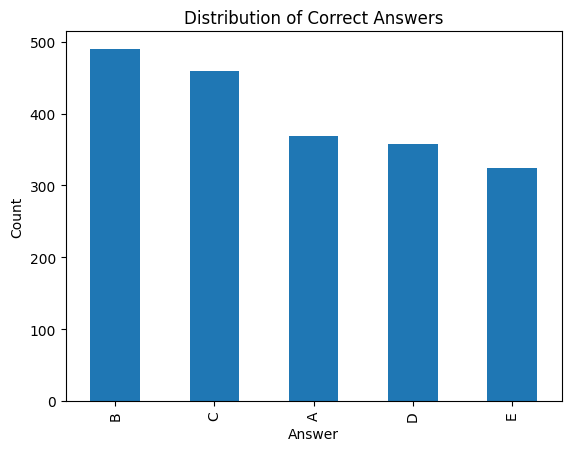

In [167]:
# Visualization

freq.plot.bar()
plt.title("Distribution of Correct Answers")
plt.xlabel("Answer")
plt.ylabel("Count")
plt.show()

## Text Length Analysis

In [168]:
# prompt Length

train["prompt_length"] = train["prompt"].str.split().str.len()
train["prompt_length"].describe()

count    2000.00000
mean       18.14650
std         6.78189
min         3.00000
25%        14.00000
50%        17.00000
75%        22.00000
max        51.00000
Name: prompt_length, dtype: float64

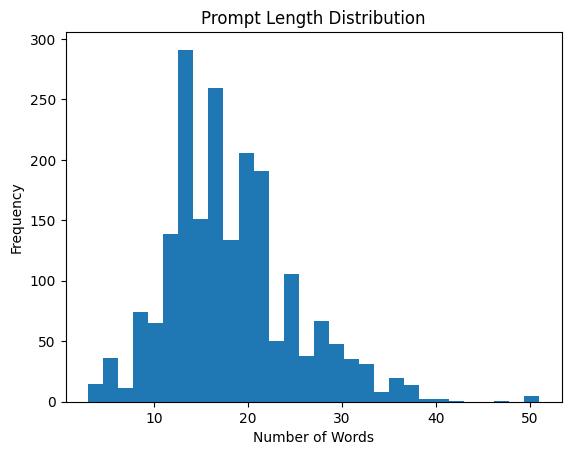

In [169]:
# histogram
plt.hist(train["prompt_length"], bins=30)
plt.title("Prompt Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [170]:
# Option Lengths
for col in ["A","B","C","D","E"]:
    train[col+"_length"] = train[col].str.split().str.len()

train[[c for c in train.columns if "length" in c]].describe()

,prompt_length,A_length,B_length,C_length,D_length,E_length
count,2000.00000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,18.14650,26.146000,26.516000,26.54950,25.999500,26.187000
std,6.78189,17.249651,18.653893,17.20987,17.098909,17.852658
min,3.00000,1.000000,1.000000,1.00000,1.000000,1.000000
25%,14.00000,13.000000,12.000000,14.75000,15.000000,13.000000
50%,17.00000,22.000000,23.000000,24.00000,22.000000,23.000000
75%,22.00000,37.000000,36.000000,36.00000,36.000000,36.000000
max,51.00000,81.000000,118.000000,82.00000,78.000000,105.000000


## Text preprocessing

The preprocessing pipeline performs:

- Lowercasing
- Removing punctuation
- Tokenization
- Stop-word removal

In [171]:
# Cleaning Function
def clean_text(text):

    text = str(text).lower()

    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    return text

In [172]:
train["clean_prompt"] = train["prompt"].apply(clean_text)

In [173]:
freq = train["answer"].value_counts()
most = freq.max()
least = freq.min()
print(freq)
print("\nAnswer:", most + least)

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

Answer: 814


## Vocabulary Analysis

In [174]:
# Vocabulary Size
vocab = set()

for text in train["clean_prompt"]:
    vocab.update(text.split())

print("Vocabulary Size:", len(vocab))

Vocabulary Size: 859


## Stop Word Removal

In [175]:
row1 = train[train["id"]==1].iloc[0]
words = row1["clean_prompt"].split()
filtered = [
    w
    for w in words
    if w not in ENGLISH_STOP_WORDS
]
print(filtered)

print(len(filtered))

['pick', 'best', 'possible', 'answer', 'martin', 'heideggers', 'view', 'relationship', 'time', 'human', 'existence', 'listed', 'options']
13


## TF-IDF Feature Extraction

In [176]:
# Combine Prompt + Options

combined = []

for _, row in train.iterrows():
    combined.append(
        " ".join(
            [
                row["prompt"], row["A"], row["B"],row["C"], row["D"], row["E"]
            ]
        )
    )


vectorizer = TfidfVectorizer(stop_words="english")
vectorizer.fit(combined)
print(len(vectorizer.vocabulary_))

2762


## Cosine Similarity

In [177]:
# Row 1

row1 = train[train["id"]==1].iloc[0]
prompt = vectorizer.transform([row1["prompt"]])
optionA = vectorizer.transform([row1["A"]])
score = cosine_similarity(
    prompt,
    optionA
)[0][0]
print(round(score,4))

0.272


## TF-IDF Prediction Pipeline

In [178]:
def rank_options(row):
    prompt = vectorizer.transform([row["prompt"]])
    scores = {}
    for option in OPTIONS:
        option_vector = vectorizer.transform([row[option]])
        scores[option] = cosine_similarity(
            prompt,
            option_vector
        )[0][0]

    return sorted(
        scores,
        key=scores.get,
        reverse=True
    )

In [179]:
correct = 0
for _, row in train.iterrows():
    prediction = rank_options(row)
    if prediction[0] == row["answer"]:
        correct += 1
percentage = correct / len(train) * 100
print(round(percentage,2))

13.55


## MAP@3

In [180]:
def map3(answer,preds):
    for i,p in enumerate(preds[:3]):
        if p==answer:
            return 1/(i+1)
    return 0

## Majority Class Baseline

In [181]:
freq=train["answer"].value_counts()

top3=freq.index[:3]

scores=[]

for _,row in train.iterrows():

    scores.append(
        map3(row["answer"],top3)
    )

np.mean(scores)

np.float64(0.42125)

## TF-IDF Baseline

In [182]:
scores=[]

for _,row in train.iterrows():

    ranked=rank_options(row)

    scores.append(
        map3(
            row["answer"],
            ranked
        )
    )

np.mean(scores)

np.float64(0.2961666666666667)

In [183]:
# Q9 — Majority Class Baseline MAP@3

top3_majority = freq.index[:3].tolist()   # ['B', 'C', 'A']
majority_scores = [map_at_3(row['answer'], top3_majority) for _, row in df.iterrows()]

print(f"\n=== Q9: Majority Class Baseline ===")
print(f"Static prediction: {top3_majority}")
print(f"Overall MAP@3: {round(np.mean(majority_scores), 4)}")


=== Q9: Majority Class Baseline ===
Static prediction: ['B', 'C', 'A']
Overall MAP@3: 0.4212


In [184]:
# Q10 — TF-IDF Pipeline MAP@3

tfidf_scores = []
for _, row in df.iterrows():
    ranked = get_ranked_options(row, tfidf)
    tfidf_scores.append(map_at_3(row['answer'], ranked[:3]))

print(f"\n=== Q10: TF-IDF Pipeline MAP@3 ===")
print(f"Average MAP@3: {round(np.mean(tfidf_scores), 4)}")


=== Q10: TF-IDF Pipeline MAP@3 ===
Average MAP@3: 0.2962
